## RQ3: Predicting flight delays

# Setup

### Setup and imports

In [ ]:
from pathlib import Path
import sys
import json
import os

from sklearn.model_selection import ParameterGrid
from sklearn.metrics import confusion_matrix

import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)
from xgboost import XGBClassifier

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.config import CLEAN_PARQUET, TABLES_DIR
from src.data_loading import load_flights

In [ ]:
import warnings
# What better way to fix bugs than to silence them
warnings.filterwarnings(
    "ignore",
    message=r"Missing values detected\. Our visualizations do not currently display missing values\.",
    category=UserWarning,
    module=r"interpret\.glassbox\._ebm\._ebm",
)

### Specifying columns/features

We have to collect the features, both from data and from previous task. To make this more clear, we add this to the feature names as metadata.
This helps to figure out which features come from where

In [25]:
FLIGHTS_SRC = "flights_2024_clean.parquet"

BASELINE_COLS = [
    ("route_past_delay_rate", "derived from training data separately for each split"),
]
FLIGHT_COLS = [  # standard features from the original flight dataframe
    ("month", FLIGHTS_SRC),
    ("day_of_week", FLIGHTS_SRC),
    ("sched_hour", f"{FLIGHTS_SRC}: crs_dep_time // 100"),
    ("op_unique_carrier", FLIGHTS_SRC),
    ("distance", FLIGHTS_SRC),
]
RQ1_COLS = [
    ("route_cluster", "rq1_route_clusters_jan_jun.csv (joined on origin, dest, op_unique_carrier)"),
    ("cluster_past_delay_rate", "rq1_cluster_delay_rates_jan_jun.csv: historical_delay_rate (joined on route_cluster)"),
]
RQ2_COLS = [
    ("origin_community", "03_airports.csv: louvain (joined on origin)"),
    ("dest_community", "03_airports.csv: louvain (joined on dest)"),
    ("crosses_community", "derived: origin_community != dest_community"),
    ("origin_betweenness", "03_airports.csv: betweenness (joined on origin)"),
    ("dest_betweenness", "03_airports.csv: betweenness (joined on dest)"),
]
OTHER_COLS = [  # not features: route key for the baseline, and the target
    ("origin", FLIGHTS_SRC),
    ("dest", FLIGHTS_SRC),
    ("late_arrival", f"target, {FLIGHTS_SRC}: arr_delay >= 15"),
]

ROUTE_KEYS = ["origin", "dest", "op_unique_carrier"]

BASELINE_FEATURES = [column for column, _ in BASELINE_COLS]
FLIGHT_FEATURES = [column for column, _ in FLIGHT_COLS]
RQ1_FEATURES = [column for column, _ in RQ1_COLS]
RQ2_FEATURES = [column for column, _ in RQ2_COLS]


# Loading data

Standard flights and target

In [26]:
flights = load_flights(
    CLEAN_PARQUET,
    columns=["month", "day_of_week", "op_unique_carrier", "origin", "dest",
             "crs_dep_time", "distance", "status", "arr_delay"],
)
flights = flights.loc[flights["status"].eq("completed")].dropna(subset=["arr_delay"])
flights = flights.reset_index(drop=True)
flights["late_arrival"] = flights["arr_delay"].ge(15).astype(int)
flights["sched_hour"] = ((flights["crs_dep_time"] // 100) % 24).astype(int)
flights = flights.drop(columns=["status", "arr_delay", "crs_dep_time"])


RQ1: route clusters and historical delay rates (January–June)

In [27]:
route_clusters = pd.read_csv(TABLES_DIR / "rq1_route_clusters_jan_jun.csv")
cluster_rates = (
    pd.read_csv(TABLES_DIR / "rq1_cluster_delay_rates_jan_jun.csv")
    [["route_cluster", "historical_delay_rate"]]
    .rename(columns={"historical_delay_rate": "cluster_past_delay_rate"})
)

# Join route clusters and historical delay rates to the flights dataframe
flights = flights.merge(route_clusters, on=ROUTE_KEYS, how="left", validate="many_to_one")
flights = flights.merge(cluster_rates, on="route_cluster", how="left", validate="many_to_one")

RQ2: airport communities and betweenness 

In [28]:
airports = pd.read_csv(TABLES_DIR / "03_airports.csv")[["airport", "louvain", "betweenness"]]
for side in ["origin", "dest"]:
    features = airports.rename(columns={
        "airport": side,
        "louvain": f"{side}_community",
        "betweenness": f"{side}_betweenness",
    })
    flights = flights.merge(features, on=side, how="left", validate="many_to_one")

Making final dataframe. And adding a bit of features

In [ ]:
group_cols = ["route_cluster", "origin_community", "dest_community"]
# Encode missing groups 
for col in group_cols:
    flights[col] = flights[col].astype("Int64").astype("string").fillna("unknown")

# We aggreed on an indicator for whether a flight crosses communities
# I couldn't find it in data so we compute it from the communities of origin and destination airports
flights["crosses_community"] = flights["origin_community"].ne(flights["dest_community"]).astype(int)
rq3_df = flights[
    ["origin", "dest"] + FLIGHT_FEATURES + RQ1_FEATURES + RQ2_FEATURES + ["late_arrival"]
].copy()


Check that everything went as planed :)

In [30]:
print(f"RQ3 modeling dataframe rows: {len(rq3_df):,}")
print(f"Target rate: {rq3_df['late_arrival'].mean():.3%}")
for col in group_cols:
    print(f"Unknown {col}: {rq3_df[col].eq('unknown').mean():.2%}")

feature_groups = [
    ("Baseline", BASELINE_COLS), ("Standard flight", FLIGHT_COLS),
    ("RQ1", RQ1_COLS), ("RQ2", RQ2_COLS), ("Other (not features)", OTHER_COLS),
]


listed = [col for col, _ in FLIGHT_COLS + RQ1_COLS + RQ2_COLS + OTHER_COLS]
assert sorted(listed) == sorted(rq3_df.columns)

RQ3 modeling dataframe rows: 6,965,246
Target rate: 20.817%
Unknown route_cluster: 1.83%
Unknown origin_community: 0.00%
Unknown dest_community: 0.00%


In [ ]:
'''
Feature overview for RQ3 modeling dataframe
Note: route_past_delay_rate are supposed to be missing, we calculate them in each fold.
'''
for name, cols in feature_groups:
    print(f"\n{name}")
    for col, source in cols:
        is_col_in_df = col in rq3_df.columns
        # I know that emojies make it look like AI slop
        # But I added them here anyways, it looks cool
        print(f"    {col:<24} <- {source} {'(❌)' if not is_col_in_df else '✅'}")


Baseline
    route_past_delay_rate    <- derived from training data separately for each split (❌)

Standard flight
    month                    <- flights_2024_clean.parquet ✅
    day_of_week              <- flights_2024_clean.parquet ✅
    sched_hour               <- flights_2024_clean.parquet: crs_dep_time // 100 ✅
    op_unique_carrier        <- flights_2024_clean.parquet ✅
    distance                 <- flights_2024_clean.parquet ✅

RQ1
    route_cluster            <- rq1_route_clusters_jan_jun.csv (joined on origin, dest, op_unique_carrier) ✅
    cluster_past_delay_rate  <- rq1_cluster_delay_rates_jan_jun.csv: historical_delay_rate (joined on route_cluster) ✅

RQ2
    origin_community         <- 03_airports.csv: louvain (joined on origin) ✅
    dest_community           <- 03_airports.csv: louvain (joined on dest) ✅
    crosses_community        <- derived: origin_community != dest_community ✅
    origin_betweenness       <- 03_airports.csv: betweenness (joined on origin) ✅
    de

### Feature groups

In [4]:
for name, features in [
    ("Baseline", BASELINE_FEATURES),
    ("standard_flight", FLIGHT_FEATURES),
    ("RQ1", RQ1_FEATURES),
    ("RQ2", RQ2_FEATURES),
]:
    print(f"{name}: {features}")

Baseline: ['route_past_delay_rate']
standard_flight: ['month', 'day_of_week', 'sched_hour', 'op_unique_carrier', 'distance']
RQ1: ['route_cluster', 'cluster_past_delay_rate']
RQ2: ['origin_community', 'dest_community', 'crosses_community', 'origin_betweenness', 'dest_betweenness']


### Feature configurations

We need a better format to pick features, so we keep them in the FEATURE_CONFIGS dictionary, so we can pick and choose later

In [5]:
# Helper function to combine features without duplicates
def combine_features(*feature_lists):
    return list(dict.fromkeys(
        col
        for features in feature_lists
        for col in features
    ))


FEATURE_CONFIGS = {
    "Baseline": BASELINE_FEATURES,
    "standard_flight": FLIGHT_FEATURES,
    "RQ1": RQ1_FEATURES,
    "RQ2": RQ2_FEATURES,

    "Baseline + standard_flight": combine_features(
        BASELINE_FEATURES,
        FLIGHT_FEATURES
    ),

    "Baseline + RQ1": combine_features(
        BASELINE_FEATURES,
        FLIGHT_FEATURES,
        RQ1_FEATURES
    ),

    "Baseline + RQ2": combine_features(
        BASELINE_FEATURES,
        FLIGHT_FEATURES,
        RQ2_FEATURES
    ),

    "Baseline + RQ1 + RQ2": combine_features(
        BASELINE_FEATURES,
        FLIGHT_FEATURES,
        RQ1_FEATURES,
        RQ2_FEATURES
    )
}

In [33]:
# 4 Stand alone, 3 Baseline + other feature, 1 Full model
assert len(FEATURE_CONFIGS) == (4 + 3 + 1) 

# Show the number of features in each configuration
feature_config_table = pd.DataFrame([
    {"Feature Config": name, "Number of Features": len(features),
     "Features": ", ".join(features)}
    for name, features in FEATURE_CONFIGS.items()
])
display(feature_config_table)


,Feature Config,Number of Features,Features
0,Baseline,1,route_past_delay_rate
1,standard_flight,5,"month, day_of_week, sched_hour, op_unique_carr..."
2,RQ1,2,"route_cluster, cluster_past_delay_rate"
3,RQ2,5,"origin_community, dest_community, crosses_comm..."
4,Baseline + standard_flight,6,"route_past_delay_rate, month, day_of_week, sch..."
5,Baseline + RQ1,8,"route_past_delay_rate, month, day_of_week, sch..."
6,Baseline + RQ2,11,"route_past_delay_rate, month, day_of_week, sch..."
7,Baseline + RQ1 + RQ2,13,"route_past_delay_rate, month, day_of_week, sch..."


### Feature selection
Each configuration is fitted from scratch twice:

| Fold | Training months | Validation month |
| --- | --- | --- |
| July | 1–6 | 7 |
| August | 1–7 | 8 |


### Setup

In [ ]:
VALIDATION_FOLDS = (
    {"fold": "July", "train_months": tuple(range(1, 7)), "validation_month": 7},
    {"fold": "August", "train_months": tuple(range(1, 8)), "validation_month": 8},
)
MODEL_TYPE = "EBM"
SELECTION_METRIC = "PR-AUC"
RANDOM_STATE = 42
# None fits every training row. Set e.g. 200_000 for a quicker comparison;
# all configurations then receive the same sample within each fold.
SAMPLE_SIZE = 200_000
THRESHOLD = 0.5

### Functions

In [49]:
'''
    Helper funcition : Calculate historical rates for encoding.
'''
def encode(history, rows, keys, smoothing, initial_prior):
    prior = history["late_arrival"].mean()

    # January doesn't have any history, so we fall back to the initial prior if needed.
    if pd.isna(prior):
        prior = float(initial_prior)

    if keys == ["route_cluster"]:
        history = history[
            history["route_cluster"].notna() & history["route_cluster"].ne("unknown")
        ]

    stats = history.groupby(keys, observed=True, dropna=False)["late_arrival"].agg(["sum", "count"])
    stats["_rate"] = (stats["sum"] + smoothing * prior) / (stats["count"] + smoothing)
    rates = rows[keys].merge(
        stats[["_rate"]].reset_index(), on=keys, how="left",
        validate="many_to_one", sort=False,
    )["_rate"].fillna(prior)
    return pd.Series(rates.to_numpy(), index=rows.index)

In [50]:
"""
    Since we didn't have the historical rates in the dataset, because we need to compute every fold,
    we add them here after split has been defined
"""
def add_historical_rate(train, val, keys, output_col, smoothing=20, initial_prior=0.5):
    """Training uses earlier months; validation uses all training history."""
    train, val = train.copy(), val.copy()
    train[output_col] = float(initial_prior)

    for month in sorted(train["month"].unique()):
        mask = train["month"].eq(month)
        history = train[train["month"] < month]
        train.loc[mask, output_col] = encode(history, train[mask], keys, smoothing, initial_prior)

    val[output_col] = encode(train, val, keys, smoothing, initial_prior)
    return train, val

In [51]:
'''
    Make data machine-learning ready.
    ie. fix types and add historical rates for categorical features.
'''
def prepare_fold(df, fold, sample_size=None, random_state=42):
    train = df[df["month"].isin(fold["train_months"])].copy()
    val = df[df["month"].eq(fold["validation_month"])].copy()

    # Calculate rates using the full history before sampling.
    for keys, column in [
        (ROUTE_KEYS, "route_past_delay_rate"),
        (["route_cluster"], "cluster_past_delay_rate"),
    ]:
        train, val = add_historical_rate(train, val, keys, column)

    n_available = len(train)

    # Apply the requested training sample; keep validation complete.
    if sample_size is not None and sample_size < n_available:
        train = train.sample(n=sample_size, random_state=random_state).copy()

    features = list(dict.fromkeys(
        col for cols in FEATURE_CONFIGS.values() for col in cols
    ))
    categorical = train[features].select_dtypes(
        include=["object", "string", "category"]
    ).columns

    for col in categorical:
        train[col] = train[col].astype("category").cat.remove_unused_categories()
        categories = train[col].cat.categories

        # Explicitly replace unseen categories before casting.
        val[col] = (
            val[col]
            .where(val[col].isin(categories), other=pd.NA)
            .astype(train[col].dtype)
        )

    print(
        f"{fold['fold']}: training on {len(train):,}/{n_available:,} rows; "
        f"validating on {len(val):,} rows",
        flush=True,
    )
    return train, val, n_available

In [52]:
def evaluate_model(model, X, y, threshold=0.5):
    probs = model.predict_proba(X)[:, 1]
    preds = (probs >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y, probs), # <- This is the main focus as aggreed
        "PR-AUC": average_precision_score(y, probs), # <- This is the main focus as aggreed
        "Log Loss": log_loss(y, probs, labels=[0, 1]),
        "Brier Score": brier_score_loss(y, probs), # Don't think we will use this in report, but it is useful indicator when working
        "Accuracy": accuracy_score(y, preds),
        "Precision": precision_score(y, preds, zero_division=0),
        "Recall": recall_score(y, preds, zero_division=0), # This turned out to be important for imbalanced datasets
        "F1": f1_score(y, preds, zero_division=0),
    }

### Traning the model and prediction validation

In [53]:
def run_feature_selection(df, model, sample_size=SAMPLE_SIZE):
    rows = []
    for fold in VALIDATION_FOLDS:
        train, val, n_available = prepare_fold(df, fold, sample_size, RANDOM_STATE)
        period, month = f"1–{max(fold['train_months'])}", fold["validation_month"]

        for name, features in FEATURE_CONFIGS.items():
            print(f"EBM | {name} | train {period} → validate {month}")
            start = time.perf_counter()
            model.fit(train[features], train["late_arrival"])
            duration = time.perf_counter() - start

            for split, data in (("Train", train), ("Validation", val)):
                rows.append({
                    "Estimator": "EBM", "Feature Config": name,
                    "Number of Features": len(features), "Fold": fold["fold"],
                    "Train Period": period, "Validation Month": month, "Split": split,
                    "Available Train Samples": n_available, "Train Samples": len(train),
                    "Eval Samples": len(data), "Training Seconds": duration,
                    **evaluate_model(model, data[features], data["late_arrival"], THRESHOLD),
                })

    results = pd.DataFrame(rows)
    return results

In [56]:
'''
    This was very slow so I reduced the number of bags and set n_jobs=-1 to use all available cores.
'''
model = ExplainableBoostingClassifier(
    random_state=RANDOM_STATE,
    interactions=0,
    n_jobs=-1,
    outer_bags=4,       # Fewer bagged models.
    max_bins=256,       # Coarser numerical features.
    max_rounds=3000,    # Limit boosting rounds.
)

print(f"Logical CPU cores detected: {os.cpu_count()}")
print(f"Training with n_jobs={model.n_jobs} (all available cores)", flush=True)

# WARNING : This takes a shit ton of time
# Unless of course we choose a smaller dataset
start = time.perf_counter()
results_df = run_feature_selection(rq3_df, model, sample_size=SAMPLE_SIZE)
elapsed = time.perf_counter() - start

print(f"Feature selection completed in {elapsed / 60:.1f} minutes ({elapsed:,.0f} seconds).")

validation_results = results_df[results_df["Split"] == "Validation"].copy()
display(validation_results.round(4))

Logical CPU cores detected: 32
Training with n_jobs=-1 (all available cores)
July: training on 200,000/3,403,472 rows; validating on 613,938 rows
EBM | Baseline | train 1–6 → validate 7
EBM | standard_flight | train 1–6 → validate 7
EBM | RQ1 | train 1–6 → validate 7
EBM | RQ2 | train 1–6 → validate 7
EBM | Baseline + standard_flight | train 1–6 → validate 7
EBM | Baseline + RQ1 | train 1–6 → validate 7
EBM | Baseline + RQ2 | train 1–6 → validate 7
EBM | Baseline + RQ1 + RQ2 | train 1–6 → validate 7
August: training on 200,000/4,017,410 rows; validating on 604,299 rows
EBM | Baseline | train 1–7 → validate 8
EBM | standard_flight | train 1–7 → validate 8
EBM | RQ1 | train 1–7 → validate 8
EBM | RQ2 | train 1–7 → validate 8
EBM | Baseline + standard_flight | train 1–7 → validate 8
EBM | Baseline + RQ1 | train 1–7 → validate 8
EBM | Baseline + RQ2 | train 1–7 → validate 8
EBM | Baseline + RQ1 + RQ2 | train 1–7 → validate 8
Feature selection completed in 1.6 minutes (94 seconds).


,Estimator,Feature Config,Number of Features,Fold,Train Period,Validation Month,Split,Available Train Samples,Train Samples,Eval Samples,Training Seconds,ROC-AUC,PR-AUC,Log Loss,Brier Score,Accuracy,Precision,Recall,F1
1,EBM,Baseline,1,July,1–6,7,Validation,3403472,200000,613938,0.8250,0.5867,0.3605,0.6129,0.2101,0.7038,0.0000,0.0000,0.0000
3,EBM,standard_flight,5,July,1–6,7,Validation,3403472,200000,613938,3.8325,0.6685,0.4338,0.5790,0.1971,0.7038,0.4675,0.0002,0.0004
5,EBM,RQ1,2,July,1–6,7,Validation,3403472,200000,613938,1.3704,0.5239,0.3101,0.6218,0.2136,0.7038,0.0000,0.0000,0.0000
7,EBM,RQ2,5,July,1–6,7,Validation,3403472,200000,613938,4.0871,0.5472,0.3264,0.6217,0.2134,0.7038,0.0000,0.0000,0.0000
9,EBM,Baseline + standard_flight,6,July,1–6,7,Validation,3403472,200000,613938,3.4871,0.6731,0.4426,0.5748,0.1951,0.7061,0.5721,0.0315,0.0597
11,EBM,Baseline + RQ1,8,July,1–6,7,Validation,3403472,200000,613938,4.2702,0.6725,0.4414,0.5753,0.1953,0.7058,0.5654,0.0301,0.0572
13,EBM,Baseline + RQ2,11,July,1–6,7,Validation,3403472,200000,613938,8.9769,0.6723,0.4365,0.5757,0.1955,0.7044,0.5166,0.0344,0.0645
15,EBM,Baseline + RQ1 + RQ2,13,July,1–6,7,Validation,3403472,200000,613938,11.4671,0.6716,0.4351,0.5762,0.1958,0.7044,0.5164,0.0344,0.0645
17,EBM,Baseline,1,August,1–7,8,Validation,4017410,200000,604299,1.0139,0.6015,0.3028,0.5340,0.1758,0.7653,0.0000,0.0000,0.0000
19,EBM,standard_flight,5,August,1–7,8,Validation,4017410,200000,604299,4.1118,0.6719,0.3725,0.5231,0.1718,0.7651,0.4952,0.0624,0.1109


In [57]:
print(SAMPLE_SIZE)

200000


### Feature ranking
Rank feature configurations by mean validation PR-AUC across the two groups

All other metrics, fold variability, and the train–validation gap are reported for comparison but do not affect the ranking.


In [58]:
SELECTION_METRIC = "Recall"

METRICS = [
    "PR-AUC", "ROC-AUC", "Log Loss", "Brier Score",
    "Accuracy", "Precision", "Recall", "F1"
]

In [62]:
# Average validation scores and recall for each month.
validation = validation_results.groupby("Feature Config", sort=False)
ranking = validation[METRICS].mean().add_prefix("Mean Validation ")
ranking = ranking.join(
    validation_results.pivot(
        index="Feature Config", columns="Validation Month", values=SELECTION_METRIC
    ).rename(columns={7: "July Recall", 8: "August Recall"})
)

# Compare stability, feature count, and training performance.
ranking["Validation Recall SD"] = validation[SELECTION_METRIC].std()
ranking["Number of Features"] = pd.Series({k: len(v) for k, v in FEATURE_CONFIGS.items()})
ranking["Mean Train Recall"] = (
    results_df.query("Split == 'Train'").groupby("Feature Config")[SELECTION_METRIC].mean()
)
ranking["Train–Validation Recall Gap"] = (
    ranking["Mean Train Recall"] - ranking["Mean Validation Recall"]
)

# Rank by recall, breaking ties by fewer features and then configuration name.
ranking = ranking.reset_index().sort_values(
    ["Mean Validation Recall", "Number of Features", "Feature Config"],
    ascending=[False, True, True], kind="stable", ignore_index=True,
)
ranking.insert(0, "Rank", range(1, len(ranking) + 1))

best = ranking.iloc[0]
best_config = best["Feature Config"]
best_features = FEATURE_CONFIGS[best_config].copy()

print("Don't forget the ranking metric", SELECTION_METRIC)

print(f"Selected features for EBM: {best_config}")
print(f"Mean validation recall: {best['Mean Validation Recall']:.4f}")
print(f"Features: {best_features}")
display(ranking.round(4))

Don't forget the ranking metric Recall
Selected features for EBM: Baseline + RQ2
Mean validation recall: 0.0834
Features: ['route_past_delay_rate', 'month', 'day_of_week', 'sched_hour', 'op_unique_carrier', 'distance', 'origin_community', 'dest_community', 'crosses_community', 'origin_betweenness', 'dest_betweenness']


,Rank,Feature Config,Mean Validation PR-AUC,Mean Validation ROC-AUC,Mean Validation Log Loss,Mean Validation Brier Score,Mean Validation Accuracy,Mean Validation Precision,Mean Validation Recall,Mean Validation F1,July Recall,August Recall,Validation Recall SD,Number of Features,Mean Train Recall,Train–Validation Recall Gap
0,1,Baseline + RQ2,0.4054,0.6752,0.5496,0.1839,0.7323,0.4892,0.0834,0.1351,0.0344,0.1323,0.0692,11,0.0285,-0.0549
1,2,Baseline + RQ1 + RQ2,0.4042,0.6747,0.5490,0.1837,0.7325,0.4893,0.0799,0.1309,0.0344,0.1254,0.0643,13,0.0304,-0.0495
2,3,Baseline + standard_flight,0.4104,0.6763,0.5487,0.1835,0.7341,0.5227,0.0787,0.1293,0.0315,0.1259,0.0668,6,0.0234,-0.0553
3,4,Baseline + RQ1,0.4090,0.6759,0.5479,0.1832,0.7339,0.5184,0.0740,0.1229,0.0301,0.1178,0.0620,8,0.0259,-0.0481
4,5,standard_flight,0.4032,0.6702,0.5510,0.1844,0.7344,0.4814,0.0313,0.0556,0.0002,0.0624,0.0440,5,0.0057,-0.0256
5,6,Baseline,0.3317,0.5941,0.5735,0.1929,0.7346,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1,0.0000,0.0000
6,7,RQ1,0.2779,0.5209,0.5830,0.1965,0.7346,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2,0.0000,0.0000
7,8,RQ2,0.2943,0.5484,0.5822,0.1961,0.7346,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,5,0.0000,0.0000


In [60]:
# Save the fold scores and feature ranking.
prefix = "rq3_ebm_feature_selection"
results_df.to_csv(TABLES_DIR / f"{prefix}_fold_scores.csv", index=False)
ranking.to_csv(TABLES_DIR / f"{prefix}_ranking.csv", index=False)

# Record the selected features and how they were chosen.
selection = {
    "estimator": "EBM",
    "feature_config": best_config,
    "features": best_features,
    "selection_metric": SELECTION_METRIC,
    "aggregation": "unweighted mean over validation months 7 and 8",
    "mean_validation_score": float(ranking.loc[0, f"Mean Validation {SELECTION_METRIC}"]),
    "sample_size": SAMPLE_SIZE,
    "random_state": RANDOM_STATE,
    "folds": list(VALIDATION_FOLDS),
    "reserved_test_months": [9, 10, 11, 12],
}
(TABLES_DIR / f"{prefix}_selected.json").write_text(
    json.dumps(selection, indent=2), encoding="utf-8"
)
print(f"Saved {prefix} results and selected features to {TABLES_DIR}")

Saved rq3_ebm_feature_selection results and selected features to C:\Users\huste\Documents\github\ComputationalToolsForDS\results\tables


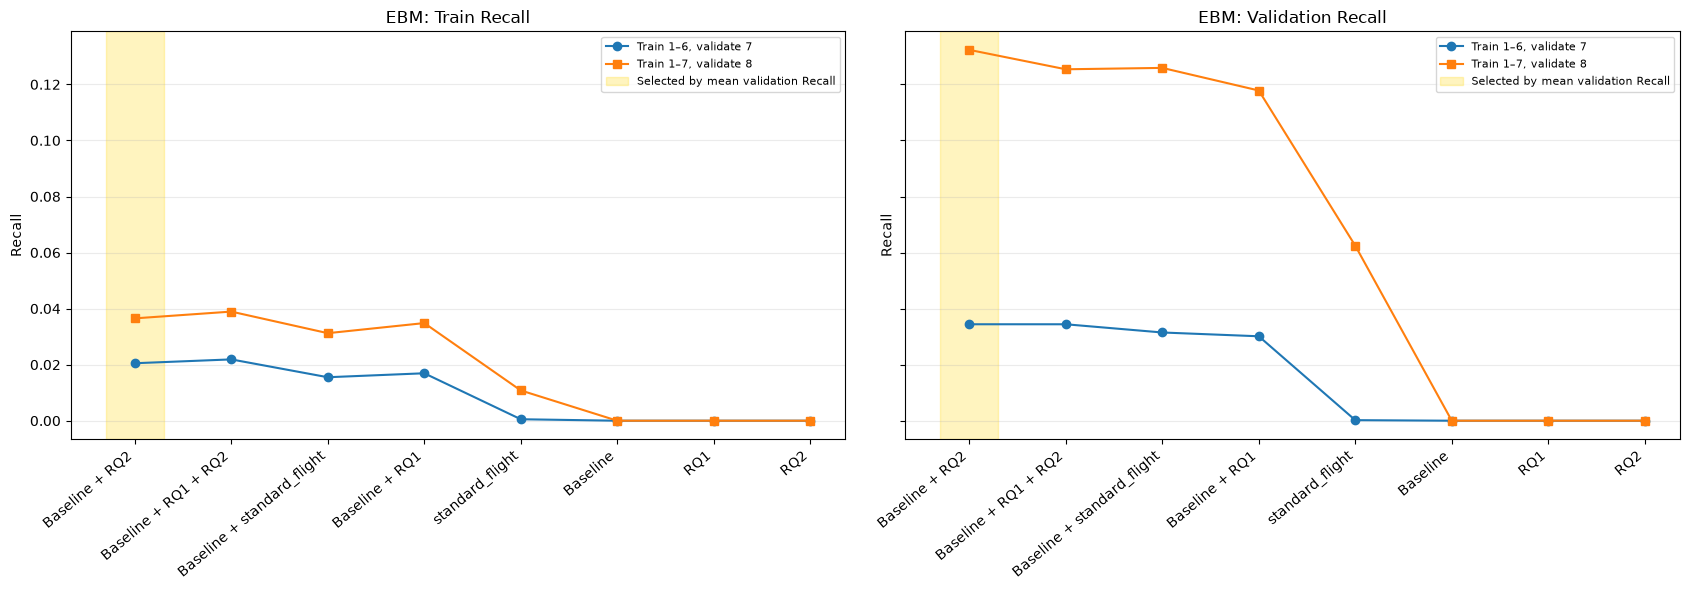

In [61]:
# Use the ranking order and highlight the selected configuration in both panels.
order = ranking["Feature Config"].tolist()
best_index = order.index(best_config)
fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)

for ax, split in zip(axes, ["Train", "Validation"]):
    scores = results_df[results_df["Split"] == split].pivot(
        index="Feature Config", columns="Validation Month", values=SELECTION_METRIC
    ).loc[order]

    for month, marker in [(7, "o"), (8, "s")]:
        ax.plot(
            order, scores[month], marker=marker,
            label=f"Train 1–{month - 1}, validate {month}",
        )

    ax.axvspan(
        best_index - 0.3, best_index + 0.3, color="gold", alpha=0.25,
        label=f"Selected by mean validation {SELECTION_METRIC}",
    )
    ax.set(title=f"EBM: {split} {SELECTION_METRIC}", ylabel=SELECTION_METRIC)
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

We picked Baseline + RQ2 based on validation recall

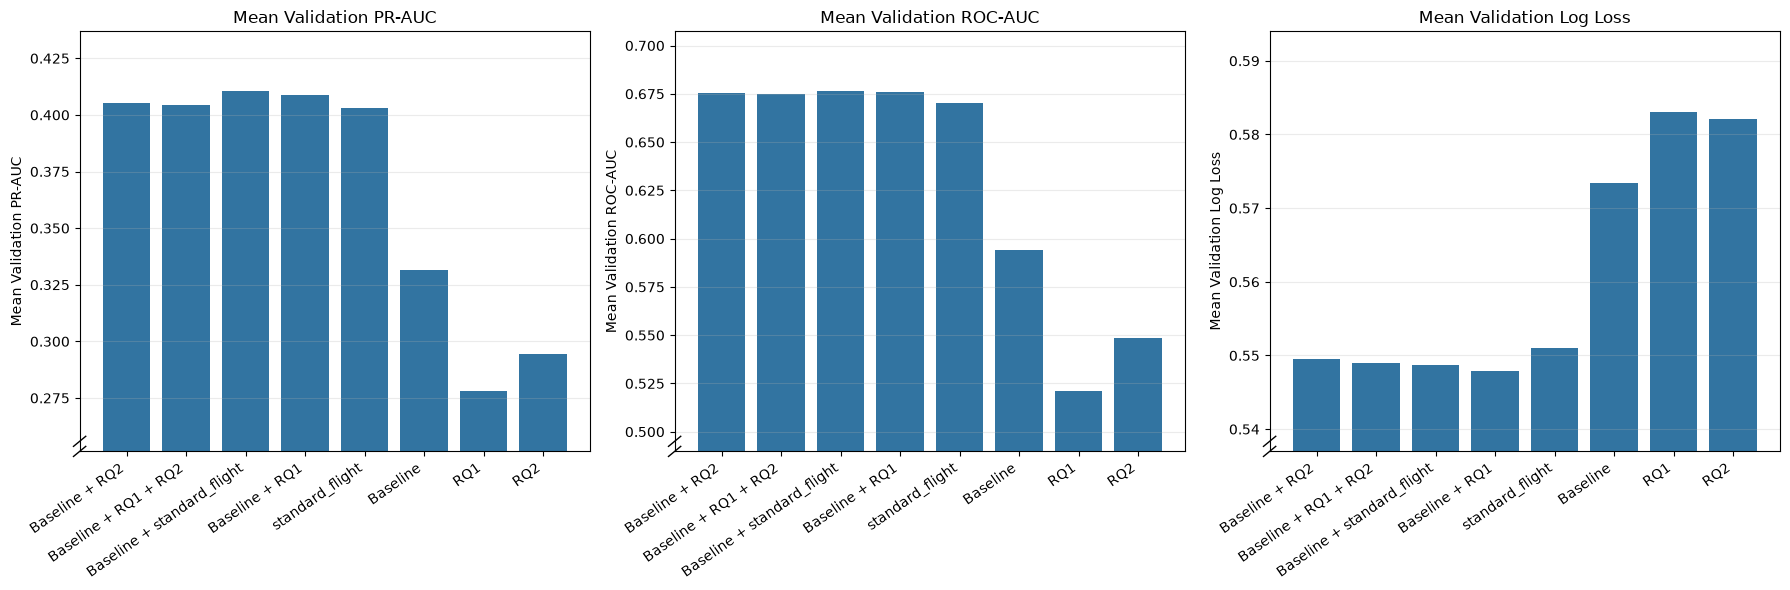

In [65]:
metrics = ["PR-AUC", "ROC-AUC", "Log Loss"]
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, metric in zip(axes, metrics):
    column = f"Mean Validation {metric}"
    sns.barplot(data=ranking, x="Feature Config", y=column,
                order=ranking["Feature Config"], ax=ax)

    # Zoom in to make differences between configurations easier to see.
    low, high = ranking[column].min(), ranking[column].max()
    padding = max((high - low) * 0.2, abs(low) * 0.02, 0.001)
    ax.set_ylim(low - padding, high + padding)

    # The slashes indicate that the y-axis does not start at zero.
    d = 0.012
    for offset in [0, 2 * d]:
        ax.plot(
            [-d, d], [-d + offset, d + offset],
            transform=ax.transAxes, color="black", clip_on=False, linewidth=1,
        )

    ax.set(title=column, xlabel="")
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
    ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

All the modesl with multiple features are almost iddentlically, so we have decided to continue with the "Baseline + RQ1 + RQ2"

In [66]:
# Save results and the exact selected feature list for subsequent modeling.
TABLES_DIR = Path("../results")
TABLES_DIR.mkdir(parents=True, exist_ok=True)


# Hyperparameter tuning
To see if we can fix some of the imbalance we saw with the low recall, we will try to do some hyperparameter turning. Especially the probabilty threshold are interesting.
Because this has a huge imact on wheter we over or underpredict positive values 

In [67]:
chosen_model = "Baseline + RQ2"


In [68]:
# Edit these lists to choose a grid; each combination is fitted once per fold.
EBM_PARAM_GRID = {
    "learning_rate": [0.015, 0.03],
    "max_leaves": [2, 3],
    "min_samples_leaf": [4],
    "interactions": [0, 3],
}
EBM_FIXED_PARAMS = {"random_state": RANDOM_STATE}
PROBABILITY_THRESHOLDS = [0.1, 0.3, 0.5, 0.7]
TUNING_SAMPLE_SIZE = 50_000 # 200.000 took way too long

print(f"Probability thresholds: {PROBABILITY_THRESHOLDS}")
print(f"Model fits: {len(ParameterGrid(EBM_PARAM_GRID))} configurations × {len(VALIDATION_FOLDS)} folds")

Probability thresholds: [0.1, 0.3, 0.5, 0.7]
Model fits: 8 configurations × 2 folds


In [69]:
def run_ebm_grid_search(df, feature_name, folds, param_grid, fixed_params,
                        thresholds, sample_size, random_state):
    features = FEATURE_CONFIGS[feature_name]
    combinations = list(ParameterGrid(param_grid))
    model_rows, threshold_rows = [], []

    for fold in folds:
        train, val, available = prepare_fold(df, fold, sample_size, random_state)
        X_train, y_train = train[features], train["late_arrival"]
        X_val, y_val = val[features], val["late_arrival"]

        for config_id, params in enumerate(combinations):
            print(f"{fold['fold']} | configuration {config_id + 1}/{len(combinations)} | {params}", flush=True)
            details = {
                "Configuration": config_id, "Fold": fold["fold"],
                "Validation Month": fold["validation_month"],
            }

            # Train once per configuration.
            model = ExplainableBoostingClassifier(**fixed_params, **params)
            start = time.perf_counter()
            model.fit(X_train, y_train)
            elapsed = time.perf_counter() - start
            probs = model.predict_proba(X_val)[:, 1]

            # Evaluate predicted probabilities.
            model_rows.append({
                **details, **params,
                "Available Train Samples": available, "Train Samples": len(train),
                "Validation Samples": len(val), "Training Seconds": elapsed,
                "ROC-AUC": roc_auc_score(y_val, probs),
                "PR-AUC": average_precision_score(y_val, probs),
                "Log Loss": log_loss(y_val, probs, labels=[0, 1]),
            })

            # Evaluate each classification threshold.
            for threshold in thresholds:
                preds = probs >= threshold
                threshold_rows.append({
                    **details, "Threshold": threshold,
                    "Recall": recall_score(y_val, preds, zero_division=0),
                    "Precision": precision_score(y_val, preds, zero_division=0),
                    "F1": f1_score(y_val, preds, zero_division=0),
                    "Positive Prediction Rate": preds.mean(),
                })

    return pd.DataFrame(model_rows), pd.DataFrame(threshold_rows)

### Running gridsearch

In [70]:
# Try each parameter combination and evaluate the probability thresholds.
tuning_folds, threshold_folds = run_ebm_grid_search(
    rq3_df, chosen_model, VALIDATION_FOLDS, EBM_PARAM_GRID, EBM_FIXED_PARAMS,
    PROBABILITY_THRESHOLDS, TUNING_SAMPLE_SIZE, RANDOM_STATE,
)

July: training on 50,000/3,403,472 rows; validating on 613,938 rows
July | configuration 1/8 | {'interactions': 0, 'learning_rate': 0.015, 'max_leaves': 2, 'min_samples_leaf': 4}
July | configuration 2/8 | {'interactions': 0, 'learning_rate': 0.015, 'max_leaves': 3, 'min_samples_leaf': 4}
July | configuration 3/8 | {'interactions': 0, 'learning_rate': 0.03, 'max_leaves': 2, 'min_samples_leaf': 4}
July | configuration 4/8 | {'interactions': 0, 'learning_rate': 0.03, 'max_leaves': 3, 'min_samples_leaf': 4}
July | configuration 5/8 | {'interactions': 3, 'learning_rate': 0.015, 'max_leaves': 2, 'min_samples_leaf': 4}
July | configuration 6/8 | {'interactions': 3, 'learning_rate': 0.015, 'max_leaves': 3, 'min_samples_leaf': 4}
July | configuration 7/8 | {'interactions': 3, 'learning_rate': 0.03, 'max_leaves': 2, 'min_samples_leaf': 4}
July | configuration 8/8 | {'interactions': 3, 'learning_rate': 0.03, 'max_leaves': 3, 'min_samples_leaf': 4}
August: training on 50,000/4,017,410 rows; valid

### Display findings

In [71]:
# Rank configurations by their average validation PR-AUC.
combinations = list(ParameterGrid(EBM_PARAM_GRID))
parameters = pd.DataFrame(combinations).rename_axis("Configuration").reset_index()
metric_names = {
    "ROC-AUC": "Mean_ROC_AUC",
    "PR-AUC": "Mean_PR_AUC",
    "Log Loss": "Mean_log_loss",
    "Training Seconds": "Mean_training_seconds",
}
tuning_ranking = (
    tuning_folds.groupby("Configuration", as_index=False)[list(metric_names)].mean()
    .rename(columns=metric_names)
    .merge(parameters, on="Configuration", validate="one_to_one")
    .sort_values(["Mean_PR_AUC", "Configuration"], ascending=[False, True], ignore_index=True)
)

best_configuration = int(tuning_ranking.loc[0, "Configuration"])
best_ebm_params = {**EBM_FIXED_PARAMS, **combinations[best_configuration]}
interaction_comparison = tuning_ranking.groupby("interactions", as_index=False).first()

# For the selected model, choose the threshold with the highest mean F1.
# If two thresholds tie, prefer the higher threshold.
selected = threshold_folds[threshold_folds["Configuration"] == best_configuration]
threshold_metrics = ["Recall", "Precision", "F1", "Positive Prediction Rate"]
threshold_ranking = (
    selected.groupby("Threshold", as_index=False)[threshold_metrics].mean()
    .sort_values(["F1", "Threshold"], ascending=[False, False], ignore_index=True)
)
best_threshold = float(threshold_ranking.loc[0, "Threshold"])

print(f"Selected EBM parameters: {best_ebm_params}")
print(f"Selected threshold by mean F1: {best_threshold}")
print("Best model for each interaction setting:")
display(interaction_comparison.round(4))
display(tuning_ranking.round(4))
display(tuning_folds.sort_values(["Configuration", "Validation Month"]).round(4))
display(threshold_ranking.round(4))



Selected EBM parameters: {'random_state': 42, 'interactions': 3, 'learning_rate': 0.015, 'max_leaves': 2, 'min_samples_leaf': 4}
Selected threshold by mean F1: 0.3
Best model for each interaction setting:


,interactions,Configuration,Mean_ROC_AUC,Mean_PR_AUC,Mean_log_loss,Mean_training_seconds,learning_rate,max_leaves,min_samples_leaf
0,0,2,0.6742,0.4048,0.5499,2.2631,0.030,2,4
1,3,4,0.6790,0.4085,0.5479,4.4811,0.015,2,4


,Configuration,Mean_ROC_AUC,Mean_PR_AUC,Mean_log_loss,Mean_training_seconds,interactions,learning_rate,max_leaves,min_samples_leaf
0,4,0.6790,0.4085,0.5479,4.4811,3,0.015,2,4
1,6,0.6790,0.4084,0.5480,3.1589,3,0.030,2,4
2,7,0.6788,0.4070,0.5480,1.6043,3,0.030,3,4
3,5,0.6786,0.4065,0.5480,2.0441,3,0.015,3,4
4,2,0.6742,0.4048,0.5499,2.2631,0,0.030,2,4
5,0,0.6741,0.4047,0.5500,4.1956,0,0.015,2,4
6,3,0.6739,0.4032,0.5498,0.7752,0,0.030,3,4
7,1,0.6737,0.4026,0.5500,1.9339,0,0.015,3,4


,Configuration,Fold,Validation Month,interactions,learning_rate,max_leaves,min_samples_leaf,Available Train Samples,Train Samples,Validation Samples,Training Seconds,ROC-AUC,PR-AUC,Log Loss
0,0,July,7,0,0.015,2,4,3403472,50000,613938,5.5914,0.6723,0.4381,0.5771
8,0,August,8,0,0.015,2,4,4017410,50000,604299,2.7998,0.6758,0.3714,0.5228
1,1,July,7,0,0.015,3,4,3403472,50000,613938,2.7305,0.6720,0.4358,0.5776
9,1,August,8,0,0.015,3,4,4017410,50000,604299,1.1374,0.6754,0.3694,0.5224
2,2,July,7,0,0.030,2,4,3403472,50000,613938,2.7695,0.6724,0.4381,0.5771
10,2,August,8,0,0.030,2,4,4017410,50000,604299,1.7566,0.6759,0.3714,0.5228
3,3,July,7,0,0.030,3,4,3403472,50000,613938,0.7258,0.6723,0.4369,0.5773
11,3,August,8,0,0.030,3,4,4017410,50000,604299,0.8246,0.6756,0.3695,0.5224
4,4,July,7,3,0.015,2,4,3403472,50000,613938,5.3830,0.6798,0.4451,0.5745
12,4,August,8,3,0.015,2,4,4017410,50000,604299,3.5792,0.6781,0.3719,0.5213


,Threshold,Recall,Precision,F1,Positive Prediction Rate
0,0.3,0.5942,0.3927,0.4642,0.4052
1,0.1,0.9657,0.2851,0.4380,0.9038
2,0.5,0.1091,0.4918,0.1651,0.0576
3,0.7,0.0025,0.4538,0.0049,0.0013


### Ranking the best parameters

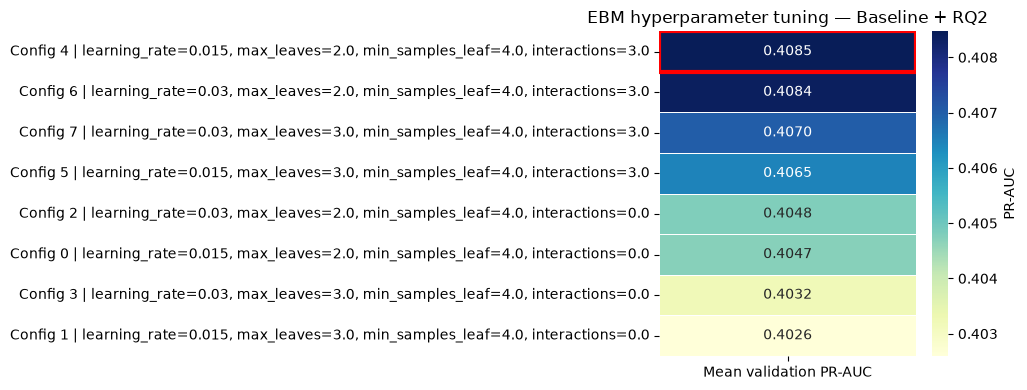

In [72]:
# Show the parameters next to each configuration so we can compare them.
heatmap_data = tuning_ranking.sort_values("Mean_PR_AUC", ascending=False).copy()
heatmap_data["Label"] = heatmap_data.apply(
    lambda row: f"Config {int(row['Configuration'])} | "
    + ", ".join(f"{p}={row[p]}" for p in EBM_PARAM_GRID),
    axis=1,
)
heatmap_data = (
    heatmap_data.set_index("Label")[["Mean_PR_AUC"]]
    .rename(columns={"Mean_PR_AUC": "Mean validation PR-AUC"})
)

fig, ax = plt.subplots(figsize=(10, max(4, len(heatmap_data) * 0.45)))
sns.heatmap(
    heatmap_data, annot=True, fmt=".4f", cmap="YlGnBu",
    linewidths=0.5, cbar_kws={"label": "PR-AUC"}, ax=ax,
)

# The best configuration is at the top; give it a red outline.
ax.add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor="red", linewidth=3))
ax.set(title=f"EBM hyperparameter tuning — {chosen_model}", xlabel="", ylabel="")
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [73]:
# Show all hyperparameter tuning results
display(tuning_ranking)

,Configuration,Mean_ROC_AUC,Mean_PR_AUC,Mean_log_loss,Mean_training_seconds,interactions,learning_rate,max_leaves,min_samples_leaf
0,4,0.678969,0.408470,0.547908,4.481062,3,0.015,2,4
1,6,0.679020,0.408393,0.547952,3.158912,3,0.030,2,4
2,7,0.678752,0.407003,0.547955,1.604308,3,0.030,3,4
3,5,0.678577,0.406457,0.547986,2.044135,3,0.015,3,4
4,2,0.674164,0.404796,0.549936,2.263055,0,0.030,2,4
5,0,0.674082,0.404722,0.549959,4.195628,0,0.015,2,4
6,3,0.673921,0.403214,0.549848,0.775193,0,0.030,3,4
7,1,0.673723,0.402597,0.549988,1.933929,0,0.015,3,4


### Rerunning the best model to see details

In [74]:
CONFIGURATION_ID = 4
tuning_dir = PROJECT_DIR / "results" / "tables"
settings = json.loads((tuning_dir / "rq3_ebm_tuning_settings.json").read_text(encoding="utf-8"))

# Replace the winning model's parameters with the configuration we want to try.
params = {
    **settings["best_ebm_params"],
    **list(ParameterGrid(settings["parameter_grid"]))[CONFIGURATION_ID],
}
features = settings["features"]
threshold = settings["best_threshold"]

rows = []
for fold in settings["folds"]:
    train, val, _ = prepare_fold(
        rq3_df, fold, settings["sample_size"], settings["random_state"]
    )
    model = ExplainableBoostingClassifier(**params)
    model.fit(train[features], train["late_arrival"])

    rows.append({
        "Fold": fold["fold"], "Validation Month": fold["validation_month"],
        "Train Samples": len(train), "Validation Samples": len(val),
        "Threshold": threshold,
        **evaluate_model(model, val[features], val["late_arrival"], threshold),
    })

scores = pd.DataFrame(rows)
mean_scores = scores.iloc[:, 5:].mean().to_frame("Mean validation score")

print(f"Configuration {CONFIGURATION_ID}: {params}")
print(f"Probability threshold: {threshold}")
display(scores.round(4))
display(mean_scores.round(4))

scores.to_csv(tuning_dir / f"rq3_ebm_config_{CONFIGURATION_ID}_metrics.csv", index=False)
print(f"Saved per-fold metrics to {tuning_dir}")

July: training on 200,000/3,403,472 rows; validating on 613,938 rows
August: training on 200,000/4,017,410 rows; validating on 604,299 rows
Configuration 4: {'random_state': 42, 'interactions': 3, 'learning_rate': 0.015, 'max_leaves': 2, 'min_samples_leaf': 4}
Probability threshold: 0.3


,Fold,Validation Month,Train Samples,Validation Samples,Threshold,ROC-AUC,PR-AUC,Log Loss,Brier Score,Accuracy,Precision,Recall,F1
0,July,7,200000,613938,0.3,0.6774,0.4411,0.5739,0.1943,0.6672,0.4476,0.5270,0.4841
1,August,8,200000,604299,0.3,0.6807,0.3743,0.5216,0.1721,0.6116,0.3363,0.6728,0.4484


,Mean validation score
ROC-AUC,0.6790
PR-AUC,0.4077
Log Loss,0.5477
Brier Score,0.1832
Accuracy,0.6394
Precision,0.3920
Recall,0.5999
F1,0.4663


Saved per-fold metrics to C:\Users\huste\Documents\github\ComputationalToolsForDS\results\tables


We evaluate configuration 4 at a fixed 0.3 threshold on the full October–December months, expanding training through the preceding month. Training uses the earlier SAMPLE_SIZE (None includes all rows). Metrics are averaged equally across months, while the confusion matrix pools all predictions. EBM term importance is averaged across folds, with missing interactions assigned zero.

In [75]:
TEST_PARAMS = {
    "random_state": 42, "interactions": 3, "learning_rate": 0.015,
    "max_leaves": 2, "min_samples_leaf": 4,
}
TEST_THRESHOLD = 0.3
TEST_FEATURES = FEATURE_CONFIGS["Baseline + RQ1 + RQ2"]
TEST_MONTHS = (10, 11, 12)

test_folds = [
    {"fold": str(month), "train_months": tuple(range(1, month)), "validation_month": month}
    for month in TEST_MONTHS
]
tables_dir = PROJECT_DIR / "results" / "tables"
figures_dir = PROJECT_DIR / "results" / "figures"
for directory in [tables_dir, figures_dir]:
    directory.mkdir(parents=True, exist_ok=True)

In [76]:
print("Chosen model:", chosen_model)
test_rows, confusion_rows, importance_rows = [], [], []
for fold in test_folds:
    month = fold["validation_month"]
    print(f"Training on months 1-{month - 1}; validating on month {month}", flush=True)
    train, val, available = prepare_fold(rq3_df, fold, SAMPLE_SIZE, TEST_PARAMS["random_state"])

    # Train on all earlier months and time the fit.
    model = ExplainableBoostingClassifier(**TEST_PARAMS)
    start = time.perf_counter()
    model.fit(train[TEST_FEATURES], train["late_arrival"])
    training_seconds = time.perf_counter() - start

    # Predict once and reuse the results for all metrics.
    y = val["late_arrival"]
    probs = model.predict_proba(val[TEST_FEATURES])[:, 1]
    preds = (probs >= TEST_THRESHOLD).astype(int)
    test_rows.append({
        "Validation Month": month, "Training Months": f"1-{month - 1}",
        "Available Train Samples": available, "Train Samples": len(train),
        "Validation Samples": len(val), "Threshold": TEST_THRESHOLD,
        "Training Seconds": training_seconds, "Base Rate": y.mean(),
        "PR-AUC": average_precision_score(y, probs),
        "ROC-AUC": roc_auc_score(y, probs),
        "Log Loss": log_loss(y, probs, labels=[0, 1]),
        "Brier Score": brier_score_loss(y, probs),
        "Accuracy": accuracy_score(y, preds),
        "Precision": precision_score(y, preds, zero_division=0),
        "Recall": recall_score(y, preds, zero_division=0),
        "F1": f1_score(y, preds, zero_division=0),
    })

    # Keep the confusion counts and term importances for the plots.
    tn, fp, fn, tp = confusion_matrix(y, preds, labels=[0, 1]).ravel()
    confusion_rows.append({"Validation Month": month, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
    importance_rows.extend(
        {"Validation Month": month, "Term": name, "Importance": importance}
        for name, importance in zip(model.term_names_, model.term_importances())
    )

Chosen model: Baseline + RQ2
Training on months 1-9; validating on month 10
10: training on 200,000/5,199,971 rows; validating on 608,513 rows
Training on months 1-10; validating on month 11
11: training on 200,000/5,808,484 rows; validating on 571,931 rows
Training on months 1-11; validating on month 12
12: training on 200,000/6,380,415 rows; validating on 584,831 rows


In [77]:
test_metrics = pd.DataFrame(test_rows)
metric_columns = [
    "Base Rate", "PR-AUC", "ROC-AUC", "Log Loss", "Brier Score",
    "Accuracy", "Precision", "Recall", "F1",
]

# Give each month the same weight, regardless of how many flights it has.
mean_row = {
    "Validation Month": "Mean",
    "Training Months": "Equal-weight mean",
    **test_metrics[metric_columns].mean().to_dict(),
}
test_metrics = pd.concat([test_metrics, pd.DataFrame([mean_row])], ignore_index=True)

test_metrics.to_csv(tables_dir / "rq3_config4_rolling_test_metrics.csv", index=False)
display(test_metrics.round(4))

,Validation Month,Training Months,Available Train Samples,Train Samples,Validation Samples,Threshold,Training Seconds,Base Rate,PR-AUC,ROC-AUC,Log Loss,Brier Score,Accuracy,Precision,Recall,F1
0,10,1-9,5199971.0,200000.0,608513.0,0.3,22.2868,0.1320,0.2014,0.6345,0.3823,0.1133,0.8322,0.2504,0.1359,0.1762
1,11,1-10,5808484.0,200000.0,571931.0,0.3,20.8106,0.1467,0.2061,0.6136,0.4129,0.1231,0.8447,0.2889,0.0400,0.0703
2,12,1-11,6380415.0,200000.0,584831.0,0.3,20.8316,0.2116,0.2877,0.6164,0.5181,0.1663,0.7839,0.3733,0.0316,0.0583
3,Mean,Equal-weight mean,NaN,NaN,NaN,NaN,NaN,0.1634,0.2317,0.6215,0.4378,0.1342,0.8203,0.3042,0.0692,0.1016


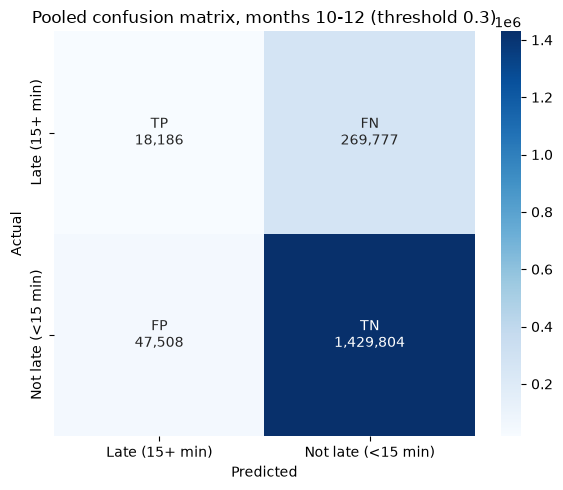

In [78]:
test_confusion = pd.DataFrame(confusion_rows)[["Validation Month", "TP", "FN", "FP", "TN"]]
test_confusion.to_csv(tables_dir / "rq3_config4_rolling_test_confusion.csv", index=False)

# Combine all three months and put late arrivals first.
pooled = test_confusion[["TP", "FN", "FP", "TN"]].sum()
matrix = pooled.to_numpy().reshape(2, 2)
labels = [[f"{name}\n{pooled[name]:,}" for name in row] for row in [("TP", "FN"), ("FP", "TN")]]
classes = ["Late (15+ min)", "Not late (<15 min)"]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    matrix, annot=labels, fmt="", cmap="Blues",
    xticklabels=classes, yticklabels=classes, ax=ax,
)
ax.set(
    title="Pooled confusion matrix, months 10-12 (threshold 0.3)",
    xlabel="Predicted", ylabel="Actual",
)

fig.tight_layout()
fig.savefig(figures_dir / "rq3_config4_rolling_test_confusion.png", dpi=150)
plt.show()

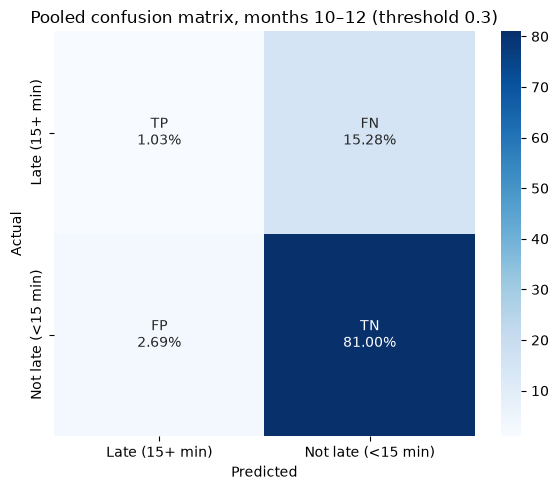

In [81]:
test_confusion = pd.DataFrame(confusion_rows)[
    ["Validation Month", "TP", "FN", "FP", "TN"]
]
test_confusion.to_csv(
    tables_dir / "rq3_config4_rolling_test_confusion.csv", index=False
)

pooled = test_confusion[["TP", "FN", "FP", "TN"]].sum()
total = pooled.sum()
if total == 0:
    raise ValueError("Cannot calculate percentages: no flights in the confusion matrix.")

percentages = pooled / total * 100
matrix = percentages.to_numpy().reshape(2, 2)
labels = [
    [f"{name}\n{percentages[name]:.2f}%" for name in row]
    for row in [("TP", "FN"), ("FP", "TN")]
]
classes = ["Late (15+ min)", "Not late (<15 min)"]

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    matrix, annot=labels, fmt="", cmap="Blues",
    xticklabels=classes, yticklabels=classes, ax=ax,
)
ax.set(
    title="Pooled confusion matrix, months 10–12 (threshold 0.3)",
    xlabel="Predicted", ylabel="Actual",
)

fig.tight_layout()
fig.savefig(figures_dir / "rq3_config4_rolling_test_confusion.png", dpi=150)
plt.show()

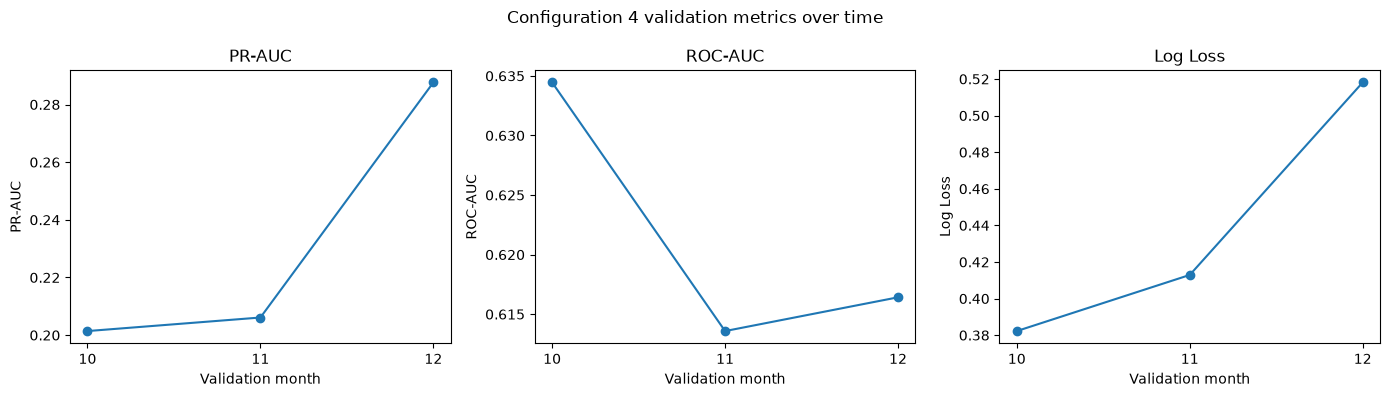

In [79]:
# Plot each month separately, leaving out the mean row.
monthly = test_metrics[test_metrics["Validation Month"] != "Mean"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, metric in zip(axes, ["PR-AUC", "ROC-AUC", "Log Loss"]):
    ax.plot(TEST_MONTHS, monthly[metric], marker="o")
    ax.set(title=metric, xlabel="Validation month", ylabel=metric, xticks=TEST_MONTHS)

fig.suptitle("Configuration 4 validation metrics over time")
fig.tight_layout()
fig.savefig(figures_dir / "rq3_config4_rolling_test_metrics.png", dpi=150)
plt.show()

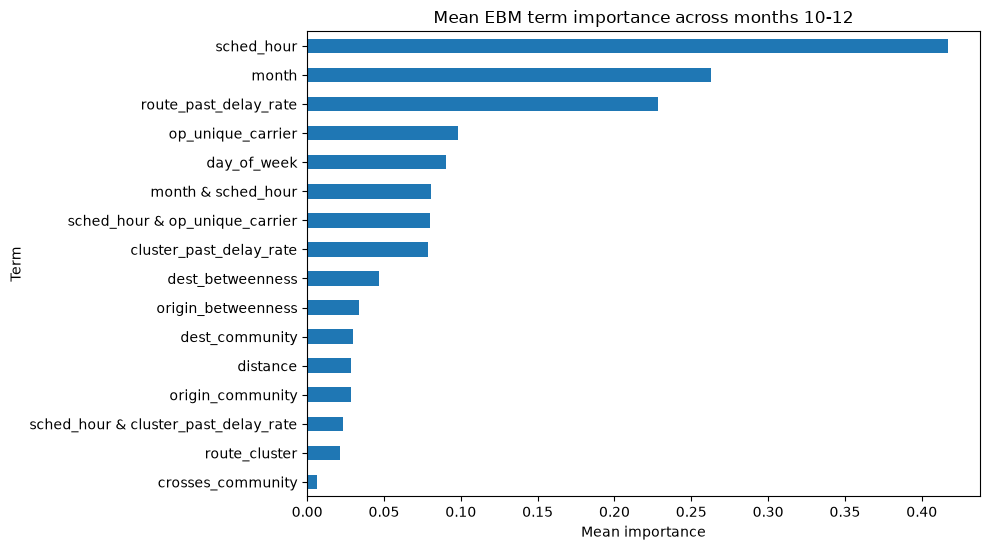

In [80]:
test_importance = pd.DataFrame(importance_rows)
test_importance.to_csv(tables_dir / "rq3_config4_rolling_test_importance.csv", index=False)

# Count missing interactions as zero so every month contributes to the average.
mean_importance = (
    test_importance.pivot(index="Term", columns="Validation Month", values="Importance")
    .reindex(columns=TEST_MONTHS, fill_value=0).fillna(0)
    .mean(axis=1).sort_values(ascending=False).rename("Mean Importance")
)
mean_importance.to_csv(tables_dir / "rq3_config4_rolling_test_mean_importance.csv")

fig, ax = plt.subplots(figsize=(10, max(4, len(mean_importance) * 0.35)))
mean_importance.sort_values().plot.barh(ax=ax)
ax.set(
    title="Mean EBM term importance across months 10-12",
    xlabel="Mean importance", ylabel="Term",
)

fig.tight_layout()
fig.savefig(figures_dir / "rq3_config4_rolling_test_importance.png", dpi=150)
plt.show()